In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
 
df = pd.read_csv('../data/Loan_approval_data_2025.csv')

### 1. Phân bố nhãn mục tiêu (`loan_status`)

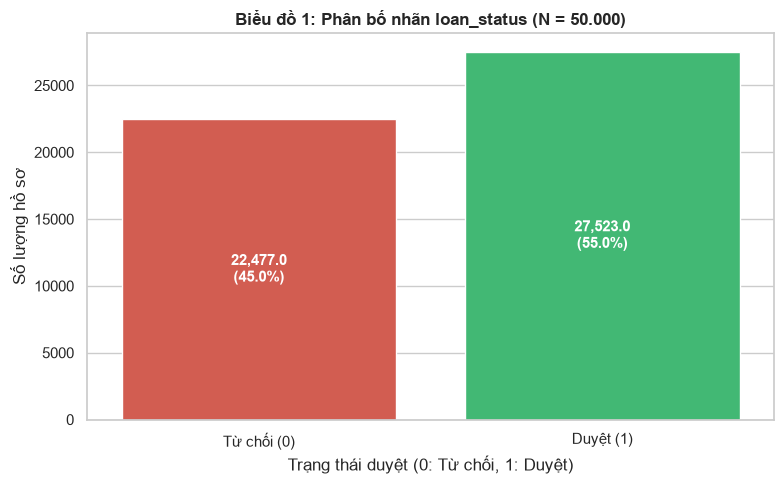

In [7]:
plt.figure(figsize=(8, 5))
ax1 = sns.countplot(x='loan_status', data=df, hue='loan_status', palette=['#e74c3c', '#2ecc71'], legend=False)
plt.title("Biểu đồ 1: Phân bố nhãn loan_status (N = 50.000)", fontsize=12, fontweight='bold')
plt.xlabel("Trạng thái duyệt (0: Từ chối, 1: Duyệt)")
plt.ylabel("Số lượng hồ sơ")
plt.xticks([0, 1], ['Từ chối (0)', 'Duyệt (1)'])

total = len(df)
for p in ax1.patches:
    h = p.get_height()
    ax1.annotate(f'{h:,}\n({h/total:.1%})', 
                 (p.get_x() + p.get_width() / 2., h / 2),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

- **Thống kê:** Trong tổng số 50.000 hồ sơ, lớp được phê duyệt ($y=1$) chiếm **55,0%** (27.523 mẫu) và lớp bị từ chối ($y=0$) chiếm **45,0%** (22.477 mẫu).
- **Ý nghĩa mô hình hóa:** Tỷ lệ nhãn ở mức xấp xỉ $1.22 : 1$, thuộc dạng dữ liệu cân bằng tốt. Dù vậy, vẫn cần sử dụng kết hợp bộ chỉ số **ROC-AUC** và **F1-Macro** để đánh giá toàn diện năng lực phân tách ranh giới của thuật toán trên mọi ngưỡng xác suất cắt, thay vì chỉ phụ thuộc vào Accuracy.

### 2. Tác động của Điểm tín dụng (`credit_score`)

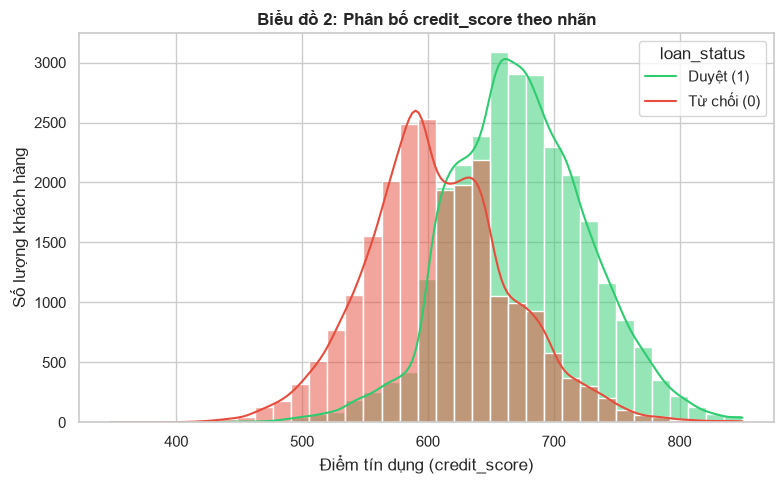

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='credit_score', hue='loan_status', kde=True, bins=35,
             palette=['#e74c3c', '#2ecc71'], alpha=0.5)
plt.title("Biểu đồ 2: Phân bố credit_score theo nhãn", fontsize=12, fontweight='bold')
plt.xlabel("Điểm tín dụng (credit_score)")
plt.ylabel("Số lượng khách hàng")
plt.legend(title="loan_status", labels=['Duyệt (1)', 'Từ chối (0)'])

plt.tight_layout()
plt.show()

- **Tương quan:** `credit_score` là đặc trưng có mối tương quan thuận mạnh nhất với việc được duyệt vay ($r = +0.496$).
- **Quy luật phân tách rõ rệt:** Những khách hàng có `credit_score` $\ge 660$ có xác suất được duyệt vay áp đảo; ngược lại, vùng điểm tín dụng dưới $600$ chủ yếu là các hồ sơ bị từ chối. Đây sẽ là đặc trưng phân chia ranh giới then chốt nhất (Root node) trong mô hình cây quyết định (Gradient Boosting).

### 3. Quy tắc loại trừ tuyệt đối từ Tiền sử nợ xấu (`defaults_on_file`)

<Figure size 800x500 with 0 Axes>

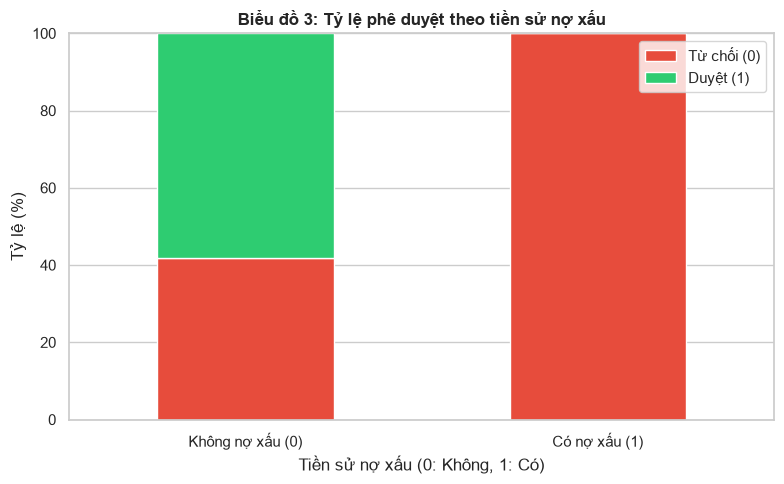

In [9]:
plt.figure(figsize=(8, 5))
cross_defaults = pd.crosstab(df['defaults_on_file'], df['loan_status'], normalize='index') * 100
ax3 = cross_defaults.plot(kind='bar', stacked=True, color=['#e74c3c', '#2ecc71'], figsize=(8, 5))
plt.title("Biểu đồ 3: Tỷ lệ phê duyệt theo tiền sử nợ xấu", fontsize=12, fontweight='bold')
plt.xlabel("Tiền sử nợ xấu (0: Không, 1: Có)")
plt.ylabel("Tỷ lệ (%)")
plt.xticks([0, 1], ['Không nợ xấu (0)', 'Có nợ xấu (1)'], rotation=0)
plt.legend(["Từ chối (0)", "Duyệt (1)"], loc='upper right')

plt.tight_layout()
plt.show()

- **Thống kê:** Trong tập dữ liệu có 2.674 khách hàng có ghi nhận nợ xấu trong quá khứ (`defaults_on_file = 1`).
- **Nhận xét chí mạng:** Toàn bộ **100,0%** (2.674/2.674) hồ sơ có `defaults_on_file = 1` đều bị **từ chối vay vốn ($y=0$)**. Không có bất kỳ ngoại lệ nào được phê duyệt. Đây là quy tắc phủ quyết cứng mang tính nghiệp vụ ngân hàng thực tế, đóng vai trò cực kỳ quan trọng khi giải thích quyết định bằng SHAP sau này.

### 4. Tương tác giữa Tỷ lệ nợ và Lãi suất (`debt_to_income_ratio` & `interest_rate`)

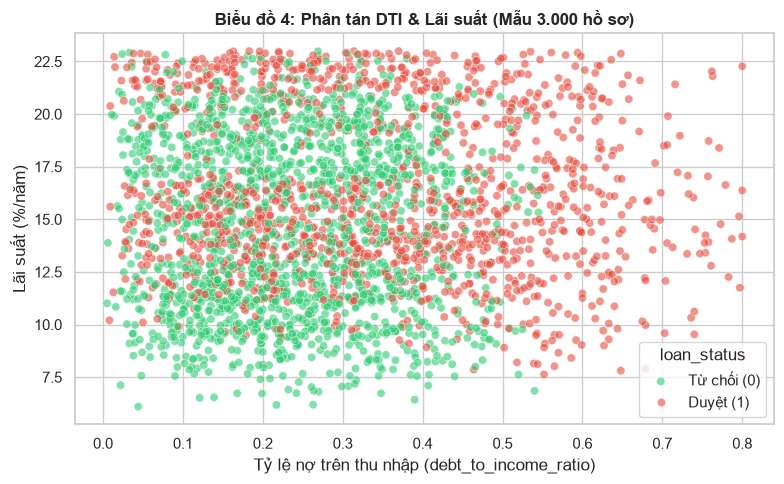

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df.sample(3000, random_state=42), 
                x='debt_to_income_ratio', y='interest_rate',
                hue='loan_status', palette=['#e74c3c', '#2ecc71'], alpha=0.6)
plt.title("Biểu đồ 4: Phân tán DTI & Lãi suất (Mẫu 3.000 hồ sơ)", fontsize=12, fontweight='bold')
plt.xlabel("Tỷ lệ nợ trên thu nhập (debt_to_income_ratio)")
plt.ylabel("Lãi suất (%/năm)")
plt.legend(title="loan_status", labels=['Từ chối (0)', 'Duyệt (1)'])

plt.tight_layout()
plt.show()

- **Tương quan:** Cả hai chỉ số này đều có mối tương quan nghịch rõ rệt với quyết định duyệt vay: `debt_to_income_ratio` ($r = -0.317$) và `interest_rate` ($r = -0.185$).
- **Quy luật phân bố:** Khi tỷ lệ nợ trên thu nhập (DTI) vượt ngưỡng **0.40** (40%) và khoản vay có lãi suất cao ($> 18\%$), mật độ hồ sơ bị từ chối (điểm màu đỏ) chiếm ưu thế áp đảo. Điều này phản ánh ngân hàng đánh giá rất nghiêm ngặt mức độ chịu nợ thực tế của người vay nhằm phòng ngừa rủi ro mất khả năng thanh toán.